# A01-DB — DBSCAN trên RFM (Standard + PCA 90%)

Thí nghiệm **A01-DB** theo chiến lược model: Clean → RFM → StandardScaler → PCA giữ ≥ 90% phương sai → DBSCAN. Đây là mốc baseline của DBSCAN, các nhánh sau (A02, A03, B…) so với kết quả này.

## Params

In [2]:
FEATURES = ["Recency", "Frequency", "Monetary"]
PCA_VAR = 0.90                      # giữ ít nhất 90% phương sai
MIN_SAMPLES_GRID = [4, 6, 8, 10, 15, 20]
EPS_GRID = [0.1, 0.2, 0.3, 0.4, 0.5, 0.7, 1.0, 1.5, 2.0]
MAX_NOISE = 0.05                    # điều kiện chọn: nhiễu tối đa 5% số khách
MIN_CLUSTERS = 2                    # điều kiện chọn: ít nhất 2 cụm (không tính nhiễu)

## Import thư viện và đọc dữ liệu

In [3]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

# Tự tìm file feature khách hàng (4.327 khách) trong repo, không phụ thuộc nơi mở notebook
REL = "notebooks/02_baseline_kmeans/12-11-2026-hieu-kmeans/data/customer_features.csv"
DATA = next(c for p in [Path.cwd(), *Path.cwd().parents]
            for c in (p / REL, p / "project" / REL) if c.exists())
FIG, OUT = Path("figure"), Path("data")
FIG.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)

df = pd.read_csv(DATA, dtype={"CustomerID": "string"})
X = df[FEATURES].copy()
assert df["CustomerID"].is_unique and X.notna().all().all() and (X >= 0).all().all()
print("Dữ liệu đầu vào:", X.shape)
X.describe().round(2)

Dữ liệu đầu vào: (4327, 3)


,Recency,Frequency,Monetary
count,4327.00,4327.00,4327.00
mean,93.04,4.25,1944.95
std,99.98,7.64,8441.89
min,1.00,1.00,2.90
25%,18.00,1.00,301.52
50%,51.00,2.00,657.90
75%,143.00,5.00,1624.10
max,374.00,206.00,278748.02


**Nhận xét:**
- Có 4.327 khách, 3 biến RFM, không thiếu giá trị và `CustomerID` không trùng.
- Dữ liệu lệch phải mạnh: Monetary trung vị 657,9 nhưng max 278.748; Frequency trung vị 2 nhưng max 206. Đây là yếu tố chi phối kết quả DBSCAN ở các bước sau.

## Chuẩn hóa và PCA giữ 90% phương sai

DBSCAN dựa trên khoảng cách nên phải scale. Không dùng log1p vì A01 là mốc gốc, log1p thuộc nhánh B.

In [4]:
X_scaled = StandardScaler().fit_transform(X)

pca_full = PCA(svd_solver="full").fit(X_scaled)
cum = np.cumsum(pca_full.explained_variance_ratio_)
n_pc = int(np.searchsorted(cum, PCA_VAR) + 1)

pca = PCA(n_components=n_pc, svd_solver="full")
Z = pca.fit_transform(X_scaled)
print("Phương sai tích lũy:", cum.round(4))
print(f"Số PC giữ lại: {n_pc} / {X.shape[1]} (phương sai giữ {cum[n_pc-1]:.2%})")

Phương sai tích lũy: [0.5638 0.8655 1.    ]
Số PC giữ lại: 3 / 3 (phương sai giữ 100.00%)


**Nhận xét:**
- 2 PC chỉ giữ 86,55% (< 90%) nên phải giữ cả 3 PC, tức là toàn bộ số biến. PC1 giải thích 56,4%.
- Với RFM thô, PCA 90% thực tế không giảm chiều.

In [5]:
# PCA giữ đủ 3/3 thành phần chỉ là phép xoay: kiểm tra DBSCAN trước và sau PCA cho cùng nhãn
lab_raw = DBSCAN(eps=0.5, min_samples=6).fit_predict(X_scaled)
lab_pca = DBSCAN(eps=0.5, min_samples=6).fit_predict(Z)
print("ARI (trước PCA vs sau PCA):", adjusted_rand_score(lab_raw, lab_pca))

ARI (trước PCA vs sau PCA): 1.0


**Nhận xét:**
- ARI = 1,0: nhãn trước và sau PCA giống hệt nhau.
- Giữ đủ 3/3 PC chỉ là phép xoay, khoảng cách giữa các khách không đổi nên mọi cấu hình DBSCAN đều cho cùng kết quả. Vì vậy **A01-DB ≡ A02-DB** (không PCA), và PCA 95% cũng giữ 3 PC nên A04-DB cũng tương đương.

## Chọn eps bằng đồ thị k-distance

Với mỗi `min_samples`, tính khoảng cách từ mỗi khách đến láng giềng thứ `min_samples` (tính cả chính nó, giống cách DBSCAN đếm), sắp xếp tăng dần. Điểm đồ thị bẻ cong mạnh gợi ý eps.

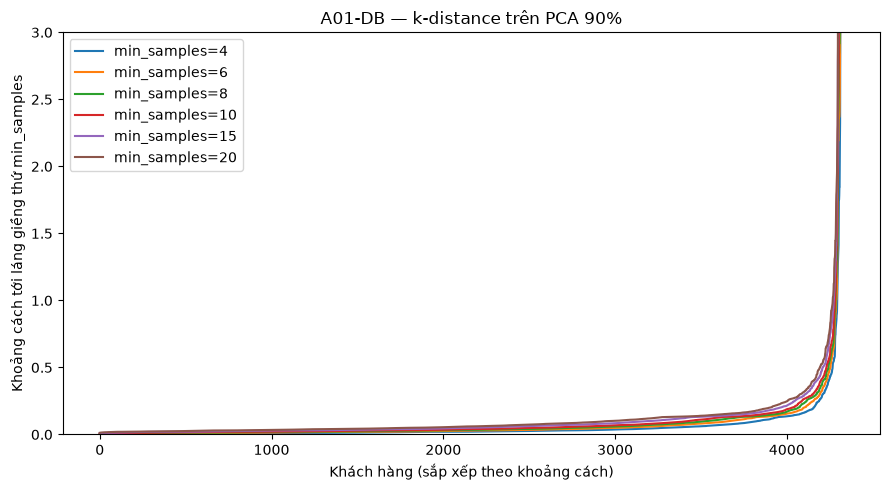

,4,6,8,10,15,20
P50,0.021,0.029,0.034,0.040,0.051,0.060
P90,0.112,0.135,0.145,0.157,0.180,0.199
P95,0.168,0.206,0.243,0.270,0.302,0.330
P99,0.742,0.898,1.002,1.073,1.272,1.443


In [6]:
kdist = {}
for ms in MIN_SAMPLES_GRID:
    d = NearestNeighbors(n_neighbors=ms).fit(Z).kneighbors(Z)[0][:, -1]
    kdist[ms] = np.sort(d)

fig, ax = plt.subplots(figsize=(9, 5))
for ms, d in kdist.items():
    ax.plot(d, label=f"min_samples={ms}")
ax.set_ylim(0, 3)
ax.set_xlabel("Khách hàng (sắp xếp theo khoảng cách)")
ax.set_ylabel("Khoảng cách tới láng giềng thứ min_samples")
ax.set_title("A01-DB — k-distance trên PCA 90%")
ax.legend()
plt.tight_layout()
plt.savefig(FIG / "k_distance.png", dpi=150)
plt.show()

pd.DataFrame({ms: np.quantile(d, [0.5, 0.9, 0.95, 0.99]) for ms, d in kdist.items()},
             index=["P50", "P90", "P95", "P99"]).round(3)

**Nhận xét:**
- Khoảng cách rất nhỏ ở phần lớn khách (P50 chỉ 0,02–0,06; P95 0,17–0,33) rồi tăng vọt ở đuôi (P99 0,74–1,44).
- Phần lớn khách nằm dày đặc quanh một vùng, khoảng 1–5% là điểm xa. Đồ thị không có khuỷu rõ ràng nên lưới eps cần phủ cả vùng nhỏ (0,1–0,3) lẫn vùng đuôi (≥ 1,0).

## Quét lưới eps × min_samples

Silhouette và DBI chỉ tính trên khách **không bị gán nhiễu** và chỉ khi có ≥ 2 cụm.

In [7]:
def run_dbscan(eps, ms):
    labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(Z)
    mask = labels != -1
    sizes = pd.Series(labels[mask]).value_counts()
    k = len(sizes)
    row = {"min_samples": ms, "eps": eps, "n_clusters": k,
           "noise_pct": round(100 * (~mask).mean(), 2),
           "largest_pct": round(100 * sizes.iloc[0] / len(Z), 2) if k else np.nan,
           "smallest": int(sizes.iloc[-1]) if k else 0,
           "silhouette": np.nan, "dbi": np.nan}
    if k >= 2:
        row["silhouette"] = round(silhouette_score(Z[mask], labels[mask]), 4)
        row["dbi"] = round(davies_bouldin_score(Z[mask], labels[mask]), 4)
    return row

grid = pd.DataFrame([run_dbscan(e, m) for m in MIN_SAMPLES_GRID for e in EPS_GRID])
print("Số cấu hình đã chạy:", len(grid))
print("Số cấu hình có >= 2 cụm:", int((grid["n_clusters"] >= 2).sum()))
print("Số cấu hình có >= 2 cụm và cụm lớn nhất < 90% khách:",
      int(((grid["n_clusters"] >= 2) & (grid["largest_pct"] < 90)).sum()))
grid[grid["n_clusters"] >= 2].sort_values("silhouette", ascending=False).head(10)

Số cấu hình đã chạy: 54
Số cấu hình có >= 2 cụm: 14
Số cấu hình có >= 2 cụm và cụm lớn nhất < 90% khách: 6


,min_samples,eps,n_clusters,noise_pct,largest_pct,smallest,silhouette,dbi
7,4,1.5,3,0.42,99.40,4,0.8177,0.4046
2,4,0.3,2,2.29,97.53,8,0.6668,0.3041
11,6,0.3,2,2.43,97.43,6,0.6596,0.2909
29,10,0.3,2,2.96,96.81,10,0.5761,0.3746
37,15,0.2,2,5.57,94.01,18,0.4542,0.4846
1,4,0.2,5,3.35,95.98,4,0.3314,0.5449
19,8,0.2,2,4.41,95.40,8,0.3200,0.5991
10,6,0.2,3,3.95,95.68,6,0.3167,0.5237
27,10,0.1,16,15.65,31.82,8,-0.2015,1.8466
45,20,0.1,10,24.17,31.78,30,-0.2436,2.1182


**Nhận xét:**
- Chỉ 14/54 cấu hình có ≥ 2 cụm.
- 6 cấu hình có cụm lớn nhất < 90% đều ở eps = 0,1, nhưng nhiễu 9–24% và Silhouette âm (−0,20 đến −0,32), nghĩa là chia vụn nên không dùng được.
- Các cấu hình còn lại đều có một cụm chiếm ≥ 94% khách. DBSCAN trên RFM thô chủ yếu tách ngoại lai, không chia khách thành các nhóm cân đối.

## Chọn cấu hình

Quy tắc chọn (đặt trước khi xem kết quả): ≥ 2 cụm, nhiễu ≤ 5% số khách, chọn **Silhouette cao nhất** trong các cấu hình thỏa.

In [8]:
valid = grid[(grid["n_clusters"] >= MIN_CLUSTERS) & (grid["noise_pct"] <= MAX_NOISE * 100)]
best = valid.sort_values("silhouette", ascending=False).iloc[0]
print("Cấu hình được chọn:")
print(best.to_string())

Cấu hình được chọn:
min_samples     4.0000
eps             1.5000
n_clusters      3.0000
noise_pct       0.4200
largest_pct    99.4000
smallest        4.0000
silhouette      0.8177
dbi             0.4046


**Nhận xét:**
- Chọn `eps = 1,5`, `min_samples = 4`: 3 cụm, nhiễu 0,42% (18 khách), Silhouette 0,8177, DBI 0,4046.
- Silhouette cao vì khối khách phổ thông (99,4%) nằm rất xa vài cụm nhỏ (4 khách/cụm), không phải vì phân khúc tốt. Không nên so con số này trực tiếp với các mô hình chia cụm cân đối.

## Hồ sơ cụm

Nhãn `-1` là nhiễu. Cột `Monetary share` là tỷ trọng tổng Monetary của nhóm.

In [9]:
labels = DBSCAN(eps=best["eps"], min_samples=int(best["min_samples"])).fit_predict(Z)
prof = X.assign(cluster=labels).groupby("cluster").agg(
    customers=("Monetary", "size"),
    Recency=("Recency", "median"),
    Frequency=("Frequency", "median"),
    Monetary=("Monetary", "median"),
    Monetary_sum=("Monetary", "sum"))
prof["customer_share_pct"] = (100 * prof["customers"] / len(X)).round(2)
prof["Monetary_share_pct"] = (100 * prof["Monetary_sum"] / prof["Monetary_sum"].sum()).round(2)
prof.drop(columns="Monetary_sum").round(1)

,customers,Recency,Frequency,Monetary,customer_share_pct,Monetary_share_pct
cluster,,,,,,
-1,18,3.0,61.0,63643.2,0.4,19.2
0,4301,52.0,2.0,654.7,99.4,76.5
1,4,3.0,54.0,35907.5,0.1,1.6
2,4,4.0,46.0,56282.3,0.1,2.7


**Nhận xét:**
- Cụm 0 (4.301 khách, 99,4%): Recency 52, Frequency 2, Monetary 654,7, gần trung vị toàn bộ nên là khách phổ thông, đóng góp 76,5% Monetary.
- Cụm 1, cụm 2 và nhóm nhiễu (tổng 26 khách, 0,6%) đều mua rất gần đây (Recency 3–4 ngày), Frequency 46–61 và Monetary 35.907–63.643, chiếm 23,5% Monetary. Đây là nhóm VIP cực lớn.

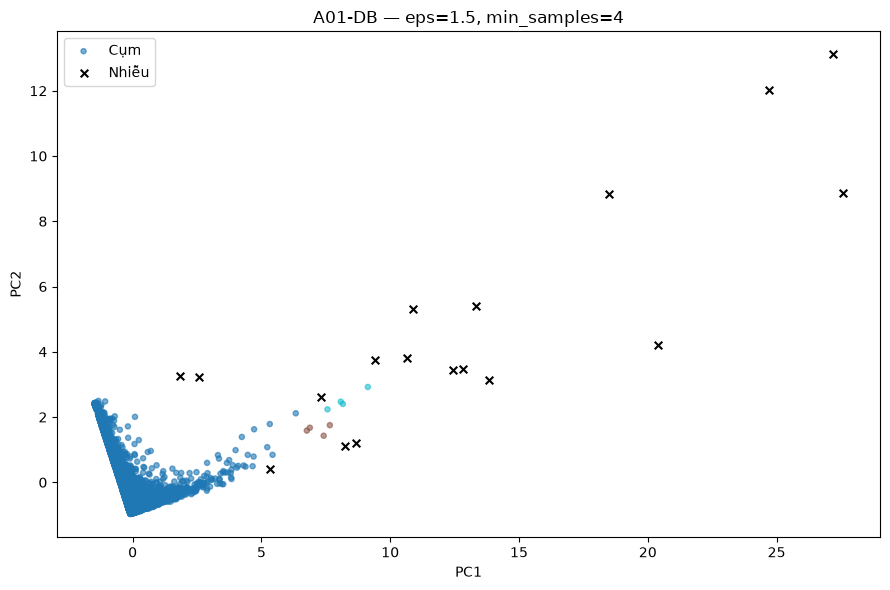

In [10]:
fig, ax = plt.subplots(figsize=(9, 6))
noise = labels == -1
ax.scatter(Z[~noise, 0], Z[~noise, 1], c=labels[~noise], cmap="tab10", s=14, alpha=0.6, label="Cụm")
ax.scatter(Z[noise, 0], Z[noise, 1], c="black", marker="x", s=30, label="Nhiễu")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.set_title(f"A01-DB — eps={best['eps']}, min_samples={int(best['min_samples'])}")
ax.legend()
plt.tight_layout()
plt.savefig(FIG / "dbscan_clusters_pca.png", dpi=150)
plt.show()

**Nhận xét:**
- Gần như toàn bộ khách dồn thành một khối ở gốc tọa độ, còn các cụm nhỏ và điểm nhiễu rải dọc đuôi PC1.
- Hình xác nhận DBSCAN chỉ tách phần đuôi ngoại lai.

## Lưu kết quả

In [11]:
grid.to_csv(OUT / "dbscan_a01_grid.csv", index=False)
pd.DataFrame({"CustomerID": df["CustomerID"], "cluster": labels}).to_csv(OUT / "dbscan_a01_labels.csv", index=False)
params = {"experiment": "A01-DB", "features": FEATURES, "scaler": "StandardScaler",
          "pca_variance": PCA_VAR, "n_components": n_pc,
          "eps": float(best["eps"]), "min_samples": int(best["min_samples"]),
          "n_clusters": int(best["n_clusters"]), "noise_pct": float(best["noise_pct"]),
          "silhouette_non_noise": float(best["silhouette"]), "dbi_non_noise": float(best["dbi"])}
json.dump(params, open(OUT / "dbscan_a01_params.json", "w", encoding="utf8"), ensure_ascii=False, indent=2)
print("Đã lưu:", sorted(p.name for p in OUT.iterdir()))

Đã lưu: ['dbscan_a01_grid.csv', 'dbscan_a01_labels.csv', 'dbscan_a01_params.json']


**Nhận xét kết luận A01-DB:**
- DBSCAN trên RFM thô + Standard + PCA 90% chỉ tách được 26 khách VIP (0,6%) khỏi khối 99,4% còn lại, tương tự K-Means baseline (cụm phổ thông 99,45%). Kết quả này không đủ để phân khúc.
- Nguyên nhân chính là phân phối lệch phải của RFM thô. Nhánh B (log1p) cần kiểm tra xem biến đổi này có làm cụm cân đối hơn không.
- Tương đương: A02-DB và A04-DB dùng lại kết quả này (PCA giữ đủ 3 PC).